# Student datasets

The four scenes from `generate_scenes.py`. Run that script first.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

SCENE_DIR = Path.cwd() / "scenes_city"
SCENES = ["blocks_0029", "canyon_0018", "courtyard_0013", "downtown_0031", "grid_0073", "hilly_0012"]

config = json.loads((SCENE_DIR / "config.json").read_text())
for k, v in config.items():
    print(f"{k:20s} {v}")

BASE_SEED            2026
AREA_SIDE            128.0
CELL                 1.0
HEIGHT_RANGE         [6.0, 55.0]
MIN_GAP              3.0
N_STATIONS           24
STATION_HEIGHT_AGL   [1.0, 10.0]
EDGE_MARGIN          5.0
BUILDING_MARGIN      2.0
GROUND_MATERIAL      medium_dry_ground
BUILDING_MATERIAL    concrete
MIN_BUILDINGS        {'blocks': 3, 'grid': 3, 'downtown': 3, 'canyon': 2, 'courtyard': 1, 'hilly': 3}
ID_FAMILIES          ['blocks', 'grid', 'downtown']
OOD_FAMILIES         ['canyon', 'courtyard', 'hilly']
ID_SPLIT             [0.8, 0.1, 0.1]
HALF                 64.0
N_CELLS              128
SEED                 2026


## Load

In [2]:
def read_ply(path):
    with open(path, "rb") as f:
        n_v = n_f = 0
        while True:
            line = f.readline().decode("ascii").strip()
            if line.startswith("element vertex"):
                n_v = int(line.split()[-1])
            elif line.startswith("element face"):
                n_f = int(line.split()[-1])
            elif line == "end_header":
                break
        v = np.frombuffer(f.read(12 * n_v), dtype="<f4").reshape(n_v, 3)
        rec = np.frombuffer(f.read(13 * n_f),
                            dtype=[("n", "u1"), ("idx", "<i4", (3,))])
    return v, rec["idx"]

data = {}
for name in SCENES:
    d = SCENE_DIR / name
    data[name] = {
        "sources": dict(np.load(d / "sources.npz")),
        "height": dict(np.load(d / "height_map.npz")),
        "meshes": {p.stem: read_ply(p) for p in sorted((d / "meshes").glob("*.ply"))},
    }
    m = data[name]["meshes"]
    print(f"{name:20s} sources {len(data[name]['sources']['ids']):5d}   "
          + "   ".join(f"{k}: {len(f)} triangles" for k, (v, f) in m.items()))

blocks_0029          sources    24   buildings: 228 triangles   ground: 2 triangles
canyon_0018          sources    24   buildings: 72 triangles   ground: 2 triangles
courtyard_0013       sources    24   buildings: 96 triangles   ground: 2 triangles
downtown_0031        sources    24   buildings: 204 triangles   ground: 2 triangles
grid_0073            sources    24   buildings: 144 triangles   ground: 2 triangles
hilly_0012           sources    24   buildings: 240 triangles   ground: 32768 triangles


## Top views
Ground height with the building in grey and the sources, coloured by height above ground.

KeyError: 'BUILDING_HEIGHT'

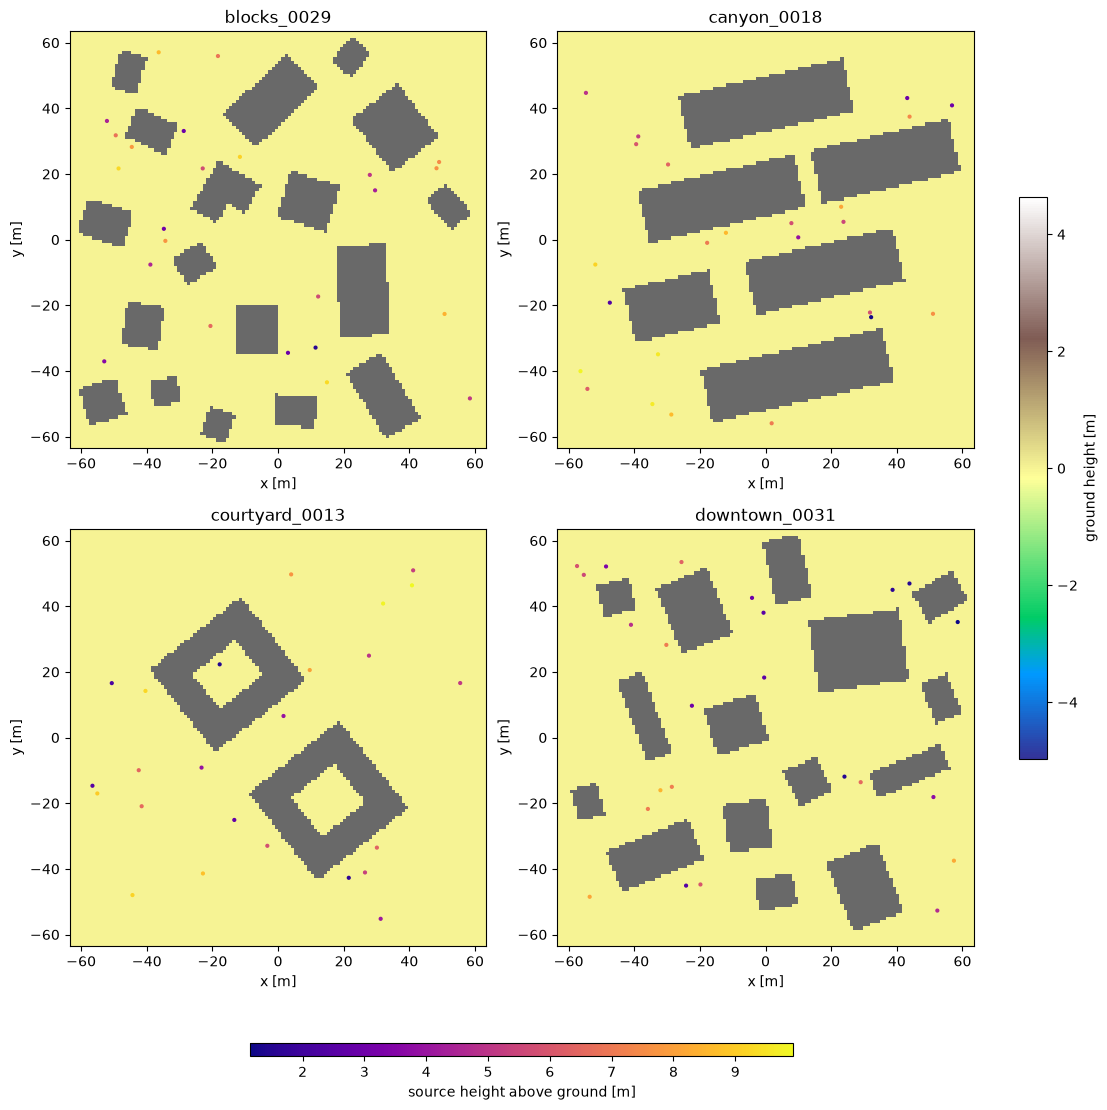

In [3]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# same colour scale in every panel, building drawn on top in grey
zmin = min(data[n]["height"]["terrain"].min() for n in SCENES)
zmax = max(data[n]["height"]["terrain"].max() for n in SCENES)
hmin = min(data[n]["sources"]["height_agl"].min() for n in SCENES)
hmax = max(data[n]["sources"]["height_agl"].max() for n in SCENES)

fig, axes = plt.subplots(2, 2, figsize=(11, 11), constrained_layout=True)
for ax, name in zip(axes.ravel(), SCENES):
    h, s = data[name]["height"], data[name]["sources"]
    extent = [h["x"][0], h["x"][-1], h["y"][0], h["y"][-1]]
    im = ax.imshow(h["terrain"], origin="lower", cmap="terrain",
                   vmin=zmin, vmax=zmax, extent=extent)
    building = np.ma.masked_where(h["surface"] <= h["terrain"], h["surface"])
    ax.imshow(building, origin="lower", cmap=ListedColormap(["dimgray"]),
              extent=extent)
    sc = ax.scatter(s["positions"][:, 0], s["positions"][:, 1], c=s["height_agl"],
                    s=4, cmap="plasma", vmin=hmin, vmax=hmax)
    ax.set_title(name)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
fig.colorbar(im, ax=axes, location="right", shrink=0.6, label="ground height [m]")
fig.colorbar(sc, ax=axes, location="bottom", shrink=0.6, aspect=40,
             label="source height above ground [m]")
fig.legend(handles=[Patch(color="dimgray",
                          label=f"building ({config['BUILDING_HEIGHT']:.0f} m)")],
           loc="outside upper center")
plt.show()

## Profiles
Cut along y = 0, through the building.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for name in SCENES:
    h = data[name]["height"]
    iy = np.argmin(np.abs(h["y"]))
    ax.plot(h["x"], h["surface"][iy], label=name)
ax.set_xlabel("x [m]")
ax.set_ylabel("height [m]")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Sources
Same sources in every scene, only z follows the terrain. For a Poisson process the nearest neighbour distance is $p(r) = 2\pi\lambda r\,e^{-\lambda\pi r^2}$.

In [ ]:
s_flat = data["blocks_0029"]["sources"]
s_irr = data["hilly_0012"]["sources"]
xy = s_flat["positions"][:, :2]
lam = config["SOURCE_DENSITY"]

d = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
np.fill_diagonal(d, np.inf)
nn = d.min(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(s_flat["height_agl"], bins=30, color="tab:blue")
axes[0].set_xlabel("height above ground [m]")
axes[0].set_ylabel("sources")

axes[1].hist(s_flat["positions"][:, 2], bins=30, alpha=0.6, label="flat")
axes[1].hist(s_irr["positions"][:, 2], bins=30, alpha=0.6, label="irregular")
axes[1].set_xlabel("absolute height z [m]")
axes[1].legend()

r = np.linspace(0, nn.max(), 200)
axes[2].hist(nn, bins=30, density=True, alpha=0.6, label="sources")
axes[2].plot(r, 2 * np.pi * lam * r * np.exp(-lam * np.pi * r ** 2), "k", label="Poisson theory")
axes[2].set_xlabel("nearest neighbour distance [m]")
axes[2].legend()
plt.tight_layout()
plt.show()

print(f"sources: {len(nn)}")
print(f"nearest neighbour distance: median {np.median(nn):.2f} m, "
      f"min {nn.min():.2f} m, max {nn.max():.2f} m")

## 3D view
Change `name` for another scene.

In [ ]:
def show_3d(name):
    fig = go.Figure()
    colors = {"ground": "darkkhaki", "building": "lightgray"}
    for key, (v, f) in data[name]["meshes"].items():
        fig.add_trace(go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2],
                                i=f[:, 0], j=f[:, 1], k=f[:, 2],
                                color=colors.get(key, "gray"), opacity=1.0,
                                name=key, flatshading=True))
    p = data[name]["sources"]["positions"]
    fig.add_trace(go.Scatter3d(x=p[:, 0], y=p[:, 1], z=p[:, 2], mode="markers",
                               marker=dict(size=2, color="red"), name="sources"))
    fig.update_layout(title=name, height=650,
                      scene=dict(aspectmode="data", xaxis_title="x [m]",
                                 yaxis_title="y [m]", zaxis_title="z [m]"))
    fig.show()

name = "blocks_0029"
show_3d(name)

## Sionna render

In [ ]:
from sionna.rt import load_scene, Camera

scene = load_scene(str(SCENE_DIR / name / f"{name}.xml"))
print("objects:", list(scene.objects.keys()))
cam = Camera(position=[-70, -70, 50], look_at=[0, 0, 0])
scene.render(camera=cam, resolution=(800, 500))
plt.show()

In [ ]:
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

CITY_DIR = Path.cwd() / "scenes_city"     # made by generate_city_scenes.py
DATA_DIR = Path.cwd() / "dataset"         # made by make_dataset.py

index = json.loads((CITY_DIR / "index.json").read_text())
print(len(index), "scenes. Families:", sorted({e["family"] for e in index}))
print("example names:", [e["name"] for e in index[:3]], "...")


def load_npz(path):
    with np.load(path) as f:
        return {k: f[k] for k in f.files}


def read_ply(path):
    with open(path, "rb") as f:
        n_v = n_f = 0
        while True:
            line = f.readline().decode("ascii").strip()
            if line.startswith("element vertex"):
                n_v = int(line.split()[-1])
            elif line.startswith("element face"):
                n_f = int(line.split()[-1])
            elif line == "end_header":
                break
        v = np.frombuffer(f.read(12 * n_v), dtype="<f4").reshape(n_v, 3)
        rec = np.frombuffer(f.read(13 * n_f), dtype=[("n", "u1"), ("idx", "<i4", (3,))])
    return v, rec["idx"]

In [ ]:
def show_saved_maps(name, station=0):
    """station = 0, 1 or 2: which of the stations chosen for this scene."""
    raw = DATA_DIR / "raw" / f"{name}.npz"
    if not raw.exists():
        print(f"no saved maps for {name}; scenes with maps:",
              sorted(p.stem for p in (DATA_DIR / "raw").glob("*.npz"))[:10], "...")
        return
    r = load_npz(raw)
    hm = load_npz(CITY_DIR / name / "height_map.npz")
    n_alt = len(set(r["altitude"].tolist()))
    ks = range(station * n_alt, (station + 1) * n_alt)
    s = r["station_pos"][ks[0]]
    fig, axes = plt.subplots(1, 1 + n_alt, figsize=(5 * (1 + n_alt), 4.6), constrained_layout=True)
    h = hm["surface"] - hm["terrain"]
    im = axes[0].imshow(np.where(h > 0.5, h, np.nan), origin="lower", cmap="magma", extent=[-64, 64, -64, 64])
    axes[0].set_facecolor("#cfe3cf")
    axes[0].plot(s[0], s[1], "c*", ms=14)
    axes[0].set_title(f"{name}: buildings [m] and station")
    fig.colorbar(im, ax=axes[0], shrink=0.8)
    for ax, k in zip(axes[1:], ks):
        alt = r["altitude"][k]
        db = np.where(hm["surface"] < alt - 0.5, r["target_db"][k], np.nan)   # cells inside buildings left white
        m = ax.imshow(db, origin="lower", cmap="viridis", vmin=-120, vmax=-60, extent=[-64, 64, -64, 64])
        ax.contour(np.linspace(-64, 64, 128), np.linspace(-64, 64, 128), h > 0.5,
                   levels=[0.5], colors="white", linewidths=0.8)
        ax.plot(s[0], s[1], "r*", ms=14)
        ax.set_title(f"altitude {alt:.0f} m ({r['rt_time'][k]:.2f} s)")
    fig.colorbar(m, ax=axes[1:], shrink=0.8, label="path gain [dB]")
    plt.show()


show_saved_maps("blocks_0000", station=0)     # change the name and the station

In [ ]:
import drjit as dr
from sionna.rt import load_scene, PlanarArray, Transmitter, RadioMapSolver, Camera

solver = RadioMapSolver()


def trace_map(name, station_id=0, altitude=30.0, samples=2_000_000, diffraction=False, max_depth=5):
    scene = load_scene(str(CITY_DIR / name / f"{name}.xml"))
    scene.frequency = 2.4e9
    scene.tx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5,
                                 horizontal_spacing=0.5, pattern="iso", polarization="V")
    scene.rx_array = scene.tx_array
    st = load_npz(CITY_DIR / name / "sources.npz")["positions"][station_id]   # 24 stations per scene: 0 to 23
    scene.add(Transmitter(name="gs", position=[float(c) for c in st]))
    t0 = time.perf_counter()
    rm = solver(scene, center=[0.0, 0.0, float(altitude)], orientation=[0.0, 0.0, 0.0], size=[128.0, 128.0],
                cell_size=[1.0, 1.0], samples_per_tx=samples, max_depth=max_depth, los=True,
                specular_reflection=True, diffuse_reflection=False, refraction=False,
                diffraction=diffraction)
    gain = np.array(rm.path_gain)[0]          # forces the computation
    dr.sync_thread()
    dt = time.perf_counter() - t0
    db = 10 * np.log10(np.maximum(gain, 1e-15))          # -150 dB = no signal
    return dict(scene=scene, rm=rm, db=db, time=dt, station=st, altitude=float(altitude), name=name,
                diffraction=diffraction)


def plot_map(res, ax=None):
    hm = load_npz(CITY_DIR / res["name"] / "height_map.npz")
    h = hm["surface"] - hm["terrain"]
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(6.2, 5.2))
    db = np.where(hm["surface"] < res["altitude"] - 0.5, res["db"], np.nan)
    m = ax.imshow(db, origin="lower", cmap="viridis", vmin=-120, vmax=-60, extent=[-64, 64, -64, 64])
    ax.contour(np.linspace(-64, 64, 128), np.linspace(-64, 64, 128), h > 0.5,
               levels=[0.5], colors="white", linewidths=0.8)
    ax.plot(res["station"][0], res["station"][1], "r*", ms=14)
    ax.set_title(f"{res['name']}, {res['altitude']:.0f} m\n"
                 f"{'with' if res['diffraction'] else 'no'} diffraction, {res['time']:.2f} s", fontsize=10)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    plt.colorbar(m, ax=ax, label="path gain [dB]", shrink=0.85)
    if own:
        plt.show()


res = trace_map("grid_0002", station_id=3, altitude=30)     # the first call is slower (compiling)
res = trace_map("grid_0002", station_id=3, altitude=30)     # second call shows the real time
plot_map(res)